<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QNN_AttackTrafficRecognition_Zhang2022.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QNN for network attack traffic recognition: Zhang, Lv and Liu (2022) step by step

This notebook re-implements, runs and checks the method of

> Meng Zhang, Bo Lv and Zi-shan Liu, "Network Attack Traffic Recognition Based on Quantum Neural Network",
> *2022 7th International Conference on Computational Intelligence and Applications (ICCIA)*, pp. 70-75, IEEE, 2022.
> DOI 10.1109/ICCIA55271.2022.9828461.

The paper publishes no code. Everything below is written from its description (Sections II and III, Figs. 1-4, Tables I-II).
The authors used **TensorFlow Quantum**, which cannot be installed on current Colab; the circuit is therefore built in **Qiskit**
(drawn, and used to test an exact closed-form simulator that does the training).

**What the notebook does.** It downloads the ten *Moore* traffic sets of the University of Cambridge (377,526 labelled flows,
248 features each, 12 application classes, one of them `ATTACK`), draws the paper's training set (Table I: 1,367 attack flows
and 1,561 other flows from sets 1, 2, 4, 7, 9, 10) and a test set from sets 3, 5, 6, 8, keeps the paper's 12 or 16 features,
turns every feature into **one qubit** (value above 0.5 gives `|1>`, otherwise `|0>`), removes conflicting flows, and trains the
paper's quantum neural network (data qubits plus one read-out qubit, two-qubit unitaries between each data qubit and the read-out
qubit). It then re-draws the loss/accuracy curves (Fig. 3) and the confusion matrices (Fig. 4), compares precision and F-score with
the paper's numbers, trains classical baselines on exactly the same inputs, and checks the paper's "bounded gradient" argument numerically.

**How to run.** Google Colab, CPU runtime, *Runtime -> Run all*. The first run downloads about 100 MB (ten gzip files) and
parses them once (several minutes); the parsed pool is cached. With `FAST_MODE = True` the training part takes a few minutes;
`FAST_MODE = False` uses the full budgets listed in the configuration cell.

**What you get at the end.** A table of per-claim verdicts ("reproduced" / "not reached" / "exceeded" / "cannot be checked"),
the classical baselines, an ablation over the two preprocessing choices the paper leaves open, and a critical reading.

## The paper in one page

**Problem.** Decide for each network flow whether it is attack traffic (label 1) or not (label 0).

**Data (Section III, Tables I and II).** The Moore data set (Moore, Zuev and Crogan, 2005): 24 hours of full-duplex traffic from a
research institution, cut into ten sample sets, 248 flow features, 12 application labels (`WWW, MAIL, FTP-CONTROL, FTP-PASV,
ATTACK, P2P, DATABASE, FTP-DATA, MULTIMEDIA, SERVICES, INTERACTIVE, GAMES`). Training: all 1,367 `ATTACK` flows of sets 1, 2, 4, 7,
9, 10 plus 1,561 flows of the other classes (Table I). Test: `ATTACK` and non-attack flows of sets 3, 5, 6, 8 (sizes not given).
Features: 12 columns (#1, #2, #15, #22, #29, #81, #158, #165, #173, #194, #230, #240) or 16 columns (those plus #231, #232, #241, #242).

**Pre-processing (Section II-B/C).** Normalise every feature to [0, 1]; keep **one qubit per feature**; the qubit is `|1>` when the
normalised value is above 0.5 and `|0>` otherwise (all decimals are dropped, "due to the limited number of qubits");
flows with identical features but different labels are removed.

**Model (Section II-D/E, Fig. 1).** `KM + 1` qubits: `KM` data qubits and one read-out qubit prepared in `|1>`. A sequence of
unitaries `U_l(theta_l)`, each acting on a subset (in the figure: two) of the qubits, is applied; the read-out qubit is measured.
Sample loss `loss(theta, q) = 1 - l(q) <q,1| U^dagger Y U |q,1>` (eq. 2); the output is rounded to 0/1 (Section II-E).
Trained with gradient steps on the TensorFlow Quantum platform.

**Claims to check.**
1. 16 features: precision 92.02 %, F-score 79.78 %. 12 features: precision 92.73 %, F-score 77.08 % (Section III).
2. Confusion matrices (Fig. 4): non-attack flows are recognised with a recall of about 95 %, attack flows only about 71 %.
3. The loss falls steadily to convergence with no jump, oscillation or NaN, "so there is no gradient explosion" (Fig. 3).
4. The gradient of the loss is bounded because every unitary has the form `exp(i theta sigma)` (eq. 3).
5. The QNN is clearly worse than a classical neural network, which the authors blame on the information thrown away by the one-qubit-per-feature binarisation.
6. Table II: the 12 features differ strongly between attack and normal traffic (ports, packet sizes, control bytes, IAT frequencies).

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Framework | TensorFlow Quantum (Cirq) | Qiskit 2.5 circuit (drawn, executed on a state-vector simulator for equivalence tests) + an **exact closed-form simulator** for training, asserted equal to the Qiskit circuit |
| Data | Moore sets 1-10 (248 features) | the same ten Weka files from the University of Cambridge |
| Training set | 1,367 attack + 1,561 other (Table I) | all 1,367 attack flows of sets 1, 2, 4, 7, 9, 10 (the count matches exactly) + the Table I quota of every other class, drawn at random from the same six sets |
| Test set | attack and non-attack of sets 3, 5, 6, 8, size not given | all 426 attack flows of those sets + about 486 non-attack flows (485 after per-class rounding) with the Table I class mix (`# CHOICE:` same attack : non-attack ratio as in training) |
| Features | #1, #2, ... (12 or 16) | the same column positions (1-based); Table II means are used to check that the positions are the paper's columns |
| Normalisation | "normalise" (no method) | `# CHOICE:` min-max or rank (quantile) normalisation, **fitted on the training split only**; chosen on a validation split of the training data |
| Binarisation | value > 0.5 gives `|1>` | identical |
| Conflicting flows | removed | `# CHOICE:` three readings are compared: remove every flow of a conflicting pattern / keep the majority label / keep all; chosen on the validation split |
| Circuit gates | generic `U_l(theta_l)` on subsets of qubits (Fig. 1) | `# CHOICE:` the TFQ QNN example: XX and ZZ couplings between every data qubit and the read-out qubit, Hadamards on the read-out qubit |
| Loss | `1 - l <Y>` (eq. 2) | `1 - l <Z_readout>` with `l = +1` (attack) / `-1` (non-attack) |
| Optimiser | gradient steps (not specified) | `# CHOICE:` Adam, learning rate 0.02, mini-batch 32, 10 or 30 epochs |
| Prediction | output rounded | attack when `<Z_readout> > 0` (the rounded value of `(1 + <Z>) / 2`) |
| Seeds | not reported | `SEED = 42`; several draws of the training/test flows and initial angles (mean +/- std) |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever the packages are missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
MISSING = [m for m in ("qiskit", "pylatexenc") if importlib.util.find_spec(m) is None]
if IN_COLAB or MISSING:
    %pip install -q "qiskit==2.5.2" pylatexenc
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit and pylatexenc already present; skipping pip install.")

qiskit and pylatexenc already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False           # True: class demo, a few minutes of training. False: full budgets below.
SEED      = 42              # CHOICE: the paper reports no seed

# ---- paper settings (identical in both modes) ----
TRAIN_SETS = [1, 2, 4, 7, 9, 10]      # paper: training flows come from these Moore sets
TEST_SETS  = [3, 5, 6, 8]             # paper: test flows come from these Moore sets
F12 = [1, 2, 15, 22, 29, 81, 158, 165, 173, 194, 230, 240]                              # paper: 12 parameters (1-based column positions)
F16 = [1, 2, 15, 22, 29, 81, 158, 165, 173, 194, 230, 231, 232, 240, 241, 242]          # paper: 16 parameters (#230~232, #240~242)
FEATURE_SETS = {12: F12, 16: F16}     # one qubit per feature -> 13 or 17 qubits including the read-out qubit
POOL_CAP = 800                        # CHOICE: candidate pool keeps all ATTACK flows and at most 800 random flows per (set, other class)

# ---- choices the paper does not specify ----
BATCH_SIZE = 32                       # CHOICE
LR         = 0.02                     # CHOICE: Adam learning rate (0.05 made the training loss jump by up to 0.07 between epochs on seed 42, 0.02 is stable)
INIT_STD   = 0.5                      # CHOICE: initial angles ~ N(0, 0.5^2)
VAL_FRACTION = 0.2                    # CHOICE: share of the training flows held out to choose the preprocessing
GRID = [(n, c) for n in ("minmax", "quantile") for c in ("drop_all", "majority", "none")]   # normalisation x conflict handling

# ---- budgets that depend on the mode ----
if FAST_MODE:
    EPOCHS, N_SEEDS, N_SEL_SEEDS = 10, 2, 1     # about 2-4 minutes of training on one CPU core
else:
    EPOCHS, N_SEEDS, N_SEL_SEEDS = 30, 5, 3     # about 15-30 minutes
TOL_PTS = 2.0                         # a claim is "reproduced" when within 2 percentage points
IBM_TOKEN = ""                        # not used: the paper ran on a simulator (TFQ), so no real-hardware cell is needed

DATA_DIR = "data"
print("FAST_MODE =", FAST_MODE, "| epochs:", EPOCHS, "| seeds:", N_SEEDS, "| selection seeds:", N_SEL_SEEDS)

FAST_MODE = False | epochs: 30 | seeds: 5 | selection seeds: 3


In [3]:
import os, time, gzip, warnings, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import QuantileTransformer, StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix

import qiskit

np.random.seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
T_NOTEBOOK_START = time.time()
print("qiskit", qiskit.__version__, "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

qiskit 2.5.2 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1


## 1. Data: the ten Moore traffic sets

The Moore data are published by the University of Cambridge as ten gzip-compressed Weka (`.arff`) files of 5-17 MB each
(`entry01 ... entry10`). Each flow has 248 numeric discriminators (missing values are `?`) and one class label. The cell below
downloads the files, streams them in chunks, and stores a compact *candidate pool*: **every** `ATTACK` flow (1,793 flows) plus up to
`POOL_CAP` randomly chosen flows of every other class in every set. The paper's own random draw (Table I quotas) is then taken from this
pool; the pool is large enough that the quotas (at most 294 flows per class) are never limited by it. The class counts of the *full* data
are kept for the exploration section. If the Cambridge server is unreachable, put the ten `entryNN.weka.allclass.arff.gz` files into
`data/moore_raw/` (upload in Colab) and run the cell again.

In [4]:
MOORE_BASES = ["https://www.cl.cam.ac.uk/research/srg/netos/projects/archive/nprobe/data/papers/sigmetrics/",
               "http://www.cl.cam.ac.uk/research/srg/netos/projects/archive/nprobe/data/papers/sigmetrics/"]
MOORE_FILE = "entry{:02d}.weka.allclass.arff.gz"
CLASS_NAMES = ["WWW", "MAIL", "FTP-CONTROL", "FTP-PASV", "ATTACK", "P2P", "DATABASE", "FTP-DATA", "MULTIMEDIA", "SERVICES", "INTERACTIVE", "GAMES"]
POOL_PATH = os.path.join(DATA_DIR, "moore_pool.npz")
RAW_DIR = os.path.join(DATA_DIR, "moore_raw")
os.makedirs(RAW_DIR, exist_ok=True)

def download_set(i):
    """Download one Moore set (gzip'd Weka ARFF, 5-17 MB) into RAW_DIR; returns its path (or None)."""
    import requests
    path = os.path.join(RAW_DIR, MOORE_FILE.format(i))
    if os.path.exists(path) and os.path.getsize(path) > 1_000_000:
        return path
    for base in MOORE_BASES:
        try:
            with requests.get(base + MOORE_FILE.format(i), stream=True, timeout=120) as r:
                r.raise_for_status()
                with open(path, "wb") as f:
                    for chunk in r.iter_content(1 << 20): f.write(chunk)
            return path
        except Exception as e:
            print("  failed:", base.split("/")[2], type(e).__name__)
    return None

def read_set_in_chunks(path, set_id, pools, counts, rng):
    """Stream one ARFF set; keep every ATTACK flow and at most POOL_CAP random flows per (set, class) of the others."""
    with gzip.open(path, "rt", errors="replace") as f:
        n_header = 0
        for line in f:
            n_header += 1
            if line.lower().startswith("@data"): break
    for chunk in pd.read_csv(path, skiprows=n_header, header=None, na_values="?", compression="gzip", chunksize=20_000):
        cls = chunk.iloc[:, 248].astype(str).to_numpy()
        # six discriminators (columns 65-68, 71, 72) are Y/N flags: CHOICE Y -> 1, N -> 0 (none of them is among the paper's 16 features)
        X = chunk.iloc[:, :248].replace({"Y": 1.0, "N": 0.0}).apply(pd.to_numeric, errors="coerce").to_numpy(dtype=np.float32)
        for c in np.unique(cls):
            counts[(set_id, c)] = counts.get((set_id, c), 0) + int((cls == c).sum())
            Xc = X[cls == c]
            key = rng.random(len(Xc)) if c != "ATTACK" else np.zeros(len(Xc))
            if (set_id, c) in pools:
                k0, X0 = pools[(set_id, c)]; key = np.concatenate([k0, key]); Xc = np.concatenate([X0, Xc])
            if c != "ATTACK" and len(key) > POOL_CAP:
                keep = np.argsort(key)[:POOL_CAP]; key, Xc = key[keep], Xc[keep]
            pools[(set_id, c)] = (key, Xc)

def build_pool():
    pools, counts, rng_pool = {}, {}, np.random.default_rng(SEED)
    for i in range(1, 11):
        t0 = time.time(); path = download_set(i)
        if path is None: raise RuntimeError(f"Moore set {i} could not be downloaded; put the ten *.arff.gz files into {RAW_DIR}")
        read_set_in_chunks(path, i, pools, counts, rng_pool)
        print(f"set {i:02d}: parsed ({time.time() - t0:.0f} s, {os.path.getsize(path) / 1e6:.1f} MB gz)")
    keys = sorted(pools)
    X = np.concatenate([pools[k][1] for k in keys]).astype(np.float32)
    set_id = np.concatenate([[k[0]] * len(pools[k][1]) for k in keys]).astype(np.int8)
    cls = np.concatenate([[k[1]] * len(pools[k][1]) for k in keys])
    ck = sorted(counts)
    np.savez_compressed(POOL_PATH, X=X, set_id=set_id, cls=cls, count_set=np.array([k[0] for k in ck]),
                        count_cls=np.array([k[1] for k in ck]), count_n=np.array([counts[k] for k in ck]))

if not os.path.exists(POOL_PATH):
    build_pool()
z = np.load(POOL_PATH, allow_pickle=False)
POOL_X, POOL_SET, POOL_CLS = z["X"], z["set_id"], z["cls"]
FULL_COUNTS = pd.DataFrame({"set": z["count_set"], "class": z["count_cls"], "flows": z["count_n"]}).pivot(index="class", columns="set", values="flows").fillna(0).astype(int)
FULL_COUNTS = FULL_COUNTS.reindex(CLASS_NAMES).fillna(0).astype(int)
print(f"candidate pool: {POOL_X.shape[0]:,} flows x {POOL_X.shape[1]} features (all ATTACK flows + up to {POOL_CAP} per other class and set)")
print(f"full Moore data: {int(FULL_COUNTS.values.sum()):,} flows in 10 sets")

candidate pool: 33,245 flows x 248 features (all ATTACK flows + up to 800 per other class and set)
full Moore data: 377,526 flows in 10 sets


### Drawing the paper's training and test flows

Training flows (Table I) come from sets 1, 2, 4, 7, 9, 10: all 1,367 `ATTACK` flows (the number matches the paper exactly, which confirms
the set assignment) and the quota of each other class. The paper does not say how many test flows it used; `# CHOICE:` all 426 attack
flows of sets 3, 5, 6, 8 and as many non-attack flows as the training ratio (1,561 : 1,367) implies, distributed over the classes in the
Table I proportions. Every random draw is controlled by `seed`; the notebook repeats the whole experiment for several seeds.

In [5]:
TABLE_I = {"WWW": 150, "MAIL": 123, "FTP-CONTROL": 149, "FTP-PASV": 43, "P2P": 294, "DATABASE": 238, "FTP-DATA": 268,
           "MULTIMEDIA": 87, "SERVICES": 206, "INTERACTIVE": 3}          # paper Table I (non-attack training flows, new label 0)
N_ATTACK_TRAIN_PAPER, N_NORMAL_TRAIN_PAPER = 1367, 1561
CLASS_COLORS = {"ATTACK": "#d62728", "WWW": "#1f77b4", "MAIL": "#2ca02c", "FTP-CONTROL": "#9467bd", "FTP-PASV": "#8c564b",
                "P2P": "#e377c2", "DATABASE": "#7f7f7f", "FTP-DATA": "#bcbd22", "MULTIMEDIA": "#17becf", "SERVICES": "#ff7f0e",
                "INTERACTIVE": "#aec7e8", "GAMES": "#000000"}

def draw_split(seed):
    """One random draw of the paper's experiment: training flows from sets 1,2,4,7,9,10 (all ATTACK flows + the Table I quota of
    every other class), test flows from sets 3,5,6,8 (all ATTACK flows + a non-attack sample with the Table I class mix)."""
    rng = np.random.default_rng(seed)
    in_train, in_test = np.isin(POOL_SET, TRAIN_SETS), np.isin(POOL_SET, TEST_SETS)
    idx_tr = [np.where(in_train & (POOL_CLS == "ATTACK"))[0]]
    for c, q in TABLE_I.items():
        cand = np.where(in_train & (POOL_CLS == c))[0]
        idx_tr.append(rng.choice(cand, size=min(q, len(cand)), replace=False))
    att_te = np.where(in_test & (POOL_CLS == "ATTACK"))[0]
    n_norm_te = int(round(len(att_te) * N_NORMAL_TRAIN_PAPER / N_ATTACK_TRAIN_PAPER))   # CHOICE: same attack : non-attack ratio as training
    idx_te = [att_te]
    for c, q in TABLE_I.items():
        cand = np.where(in_test & (POOL_CLS == c))[0]
        k = max(1, int(round(n_norm_te * q / N_NORMAL_TRAIN_PAPER)))
        idx_te.append(rng.choice(cand, size=min(k, len(cand)), replace=False))
    idx_tr, idx_te = rng.permutation(np.concatenate(idx_tr)), rng.permutation(np.concatenate(idx_te))
    return dict(seed=seed, Xtr=POOL_X[idx_tr], ytr=(POOL_CLS[idx_tr] == "ATTACK"), ctr=POOL_CLS[idx_tr], str_=POOL_SET[idx_tr],
                Xte=POOL_X[idx_te], yte=(POOL_CLS[idx_te] == "ATTACK"), cte=POOL_CLS[idx_te], ste=POOL_SET[idx_te])

SPLITS = {}
def get_split(seed):
    if seed not in SPLITS: SPLITS[seed] = draw_split(seed)
    return SPLITS[seed]

sp = get_split(SEED)
print(f"seed {SEED}: train {len(sp['ytr'])} flows ({sp['ytr'].sum()} attack / {(~sp['ytr']).sum()} non-attack) | "
      f"test {len(sp['yte'])} flows ({sp['yte'].sum()} attack / {(~sp['yte']).sum()} non-attack)")

seed 42: train 2928 flows (1367 attack / 1561 non-attack) | test 911 flows (426 attack / 485 non-attack)


## 2. Pre-processing: normalise, binarise, remove conflicts

For every feature: normalise to [0, 1] with statistics of the **training** flows only, then `value > 0.5` gives the basis state `|1>`.
The paper does not say how it normalised. Plain **min-max** scaling is the literal reading, but the Moore features are heavy tailed (ports up
to 65,535, packet sizes up to thousands of bytes): after min-max almost every flow falls below 0.5 and the bits carry little information.
A **rank (quantile) normalisation** puts 0.5 at the training median, so every bit is a balanced "above/below typical" question.
We keep both as `# CHOICE:` options. Likewise "conflicting data are removed" can mean three things (`drop_all`, `majority`, `none`).
The six combinations are compared on a validation split of the training flows (section 3); the test flows are never used to choose.

In [6]:
def prep_fit_transform(Xtr, Xte, norm):
    """Normalise to [0, 1]; every statistic is fitted on the training part only (test values are clipped / mapped with the training fit)."""
    med = np.nanmedian(Xtr, axis=0); med = np.where(np.isnan(med), 0.0, med)          # CHOICE: missing FFT values -> training median
    Xtr = np.where(np.isnan(Xtr), med, Xtr); Xte = np.where(np.isnan(Xte), med, Xte)
    if norm == "minmax":                                                              # the literal reading of "normalise" in the paper
        lo, hi = Xtr.min(axis=0), Xtr.max(axis=0); span = np.where(hi > lo, hi - lo, 1.0)
        return (Xtr - lo) / span, np.clip((Xte - lo) / span, 0.0, 1.0)
    qt = QuantileTransformer(n_quantiles=min(200, len(Xtr)), output_distribution="uniform", random_state=SEED).fit(Xtr)
    return qt.transform(Xtr), qt.transform(Xte)                                       # rank-based: 0.5 = training median

def to_bits(A):
    """Section II-C with one qubit per feature: value > 0.5 -> |1>, otherwise |0> (integer bit only, decimals dropped)."""
    return (A > 0.5).astype(np.int8)

def resolve_conflicts(B, y, mode):
    """Flows with identical bit patterns but different labels are 'conflict data' (Section II-C).
    drop_all: remove every flow of a conflicting pattern | majority: keep only the majority label of such a pattern | none: keep all."""
    key = B.astype(np.int64) @ (1 << np.arange(B.shape[1], dtype=np.int64))
    uniq, inv = np.unique(key, return_inverse=True)
    n_att = np.bincount(inv, weights=y.astype(float)); n_nor = np.bincount(inv, weights=(~y).astype(float))
    mixed = ((n_att > 0) & (n_nor > 0))[inv]
    if mode == "none": keep = np.ones(len(y), dtype=bool)
    elif mode == "drop_all": keep = ~mixed
    elif mode == "majority": keep = ~mixed | ((n_att > n_nor)[inv] == y) & (n_att != n_nor)[inv]
    else: raise ValueError(mode)
    return B[keep], y[keep], int(mixed.sum())

def attack_metrics(y, pred):
    """Attack = positive class. Percentages."""
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[False, True]).ravel()
    P = tp / (tp + fp) if tp + fp else 0.0; R = tp / (tp + fn) if tp + fn else 0.0
    F = 2 * P * R / (P + R) if P + R else 0.0
    return dict(accuracy=100 * (tp + tn) / len(y), precision=100 * P, recall=100 * R, f1=100 * F,
                tnr=100 * tn / (tn + fp) if tn + fp else 0.0, tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

## Dataset Exploration and Visualisation

Everything in this section is computed from the real Moore flows. The data are not images or sequences, so the labelled 2-D projections
below are PCA projections of the flow features (fitted on the training flows only); test flows are projected with the training fit and drawn
as crosses. The model does **not** use angle encoding (a feature becomes the basis state `|0>` or `|1>`, i.e. an `X` gate), so there is no
"scaled to [0, pi]" plot; instead the PCA of the **binary patterns the circuit actually receives** is shown.

candidate pool shape: (33245, 248)  (flows x features; features are the 248 numeric Moore discriminators, 1-based column positions 1..248)
features used by the paper (12): [1, 2, 15, 22, 29, 81, 158, 165, 173, 194, 230, 240]
features used by the paper (16): [1, 2, 15, 22, 29, 81, 158, 165, 173, 194, 230, 231, 232, 240, 241, 242]
original label values: ['WWW', 'MAIL', 'FTP-CONTROL', 'FTP-PASV', 'ATTACK', 'P2P', 'DATABASE', 'FTP-DATA', 'MULTIMEDIA', 'SERVICES', 'INTERACTIVE', 'GAMES']


,feature (name as far as the paper's Table II gives it)
#1,server port
#2,client port
#15,max Ethernet packet bytes (as in the paper's T...
#22,max IP packet bytes
#29,max control bytes
#81,max segment size c->s
#158,max Ethernet packet bytes (2nd listing)
#165,max IP packet bytes (2nd listing)
#173,variance of control bytes c->s
#194,variance of control bytes s->c



flows per class and Moore set (full data):


set,1,2,3,4,5,6,7,8,9,10,total
class,,,,,,,,,,,
WWW,18211,18559,18065,19641,18618,16892,51982,51695,59993,54436,328092
MAIL,4146,2726,1448,1429,1651,1618,2771,2508,3678,6592,28567
FTP-CONTROL,149,100,1861,94,500,48,83,63,75,81,3054
FTP-PASV,43,344,125,22,180,109,94,102,1412,257,2688
ATTACK,122,19,41,324,122,134,89,129,367,446,1793
P2P,339,94,100,114,75,94,116,289,249,624,2094
DATABASE,238,329,206,8,0,0,36,43,15,1773,2648
FTP-DATA,1319,1257,750,484,248,364,307,386,90,592,5797
MULTIMEDIA,87,150,136,54,38,42,36,33,0,0,576


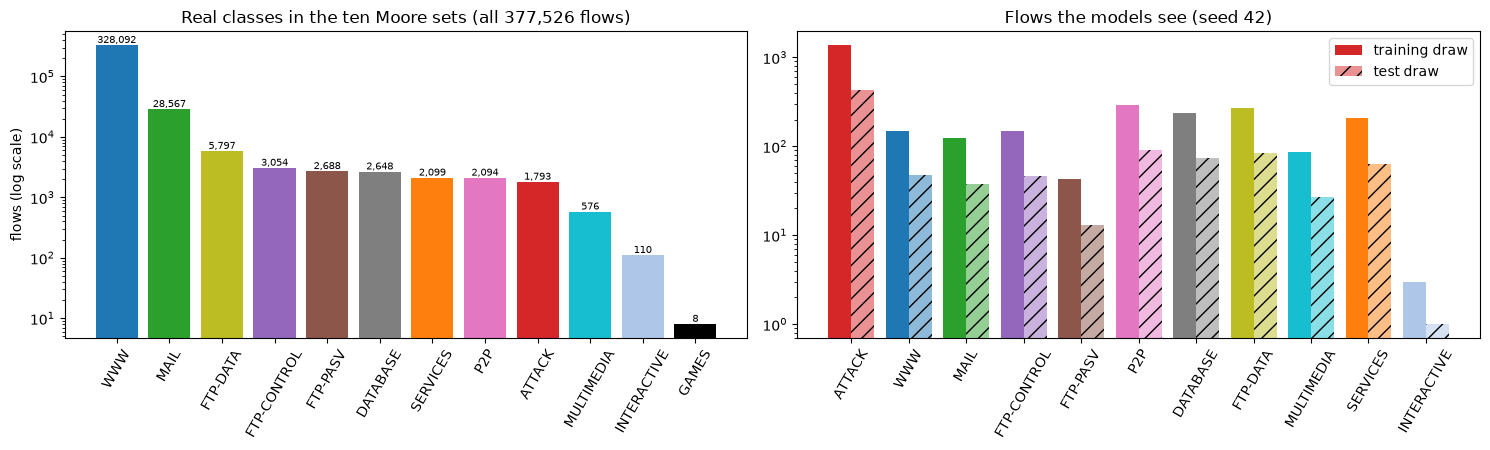

,paper Table I,this training draw,equal
ATTACK,1367,1367,True
WWW,150,150,True
MAIL,123,123,True
FTP-CONTROL,149,149,True
FTP-PASV,43,43,True
P2P,294,294,True
DATABASE,238,238,True
FTP-DATA,268,268,True
MULTIMEDIA,87,87,True
SERVICES,206,206,True


training composition identical to the paper's Table I: True


In [7]:
FEATURE_NAMES = {1: "server port", 2: "client port", 15: "max Ethernet packet bytes (as in the paper's Table II)", 22: "max IP packet bytes",
                 29: "max control bytes", 81: "max segment size c->s", 158: "max Ethernet packet bytes (2nd listing)", 165: "max IP packet bytes (2nd listing)",
                 173: "variance of control bytes c->s", 194: "variance of control bytes s->c", 230: "FFT of packet IAT, frequency #2 (c->s)",
                 231: "(column 231, not described in Table II)", 232: "(column 232, not described in Table II)", 240: "FFT of packet IAT, frequency #2 (s->c)",
                 241: "(column 241, not described in Table II)", 242: "(column 242, not described in Table II)"}
print(f"candidate pool shape: {POOL_X.shape}  (flows x features; features are the 248 numeric Moore discriminators, 1-based column positions 1..248)")
print("features used by the paper (12):", F12)
print("features used by the paper (16):", F16)
print("original label values:", CLASS_NAMES)
display(pd.Series({f"#{f}": FEATURE_NAMES[f] for f in F16}, name="feature (name as far as the paper's Table II gives it)").to_frame())

tot = FULL_COUNTS.copy(); tot["total"] = tot.sum(axis=1); tot.loc["ALL CLASSES"] = tot.sum(axis=0)
print("\nflows per class and Moore set (full data):")
display(tot)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
cnt = FULL_COUNTS.sum(axis=1).sort_values(ascending=False)
axes[0].bar(cnt.index, cnt.values, color=[CLASS_COLORS[c] for c in cnt.index]); axes[0].set_yscale("log")
axes[0].set_ylabel("flows (log scale)"); axes[0].set_title("Real classes in the ten Moore sets (all 377,526 flows)")
axes[0].tick_params(axis="x", rotation=60)
for i, v in enumerate(cnt.values): axes[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=7)
ctr = pd.Series(sp["ctr"]).value_counts(); cte = pd.Series(sp["cte"]).value_counts()
order = ["ATTACK"] + list(TABLE_I)
xs = np.arange(len(order)); w = 0.4
axes[1].bar(xs - w / 2, [ctr.get(c, 0) for c in order], w, label="training draw", color=[CLASS_COLORS[c] for c in order])
axes[1].bar(xs + w / 2, [cte.get(c, 0) for c in order], w, label="test draw", color=[CLASS_COLORS[c] for c in order], alpha=0.5, hatch="//")
axes[1].set_xticks(xs); axes[1].set_xticklabels(order, rotation=60); axes[1].set_title(f"Flows the models see (seed {SEED})"); axes[1].legend()
axes[1].set_yscale("log")
plt.tight_layout(); plt.show()

table1 = pd.DataFrame({"paper Table I": {**{"ATTACK": N_ATTACK_TRAIN_PAPER}, **TABLE_I}, "this training draw": {c: int(ctr.get(c, 0)) for c in order}})
table1["equal"] = table1.iloc[:, 0] == table1.iloc[:, 1]
display(table1)
print("training composition identical to the paper's Table I:", bool(table1["equal"].all()))

In [8]:
# Table II of the paper: mean values of the 12 features for attack and normal traffic. We recompute them on our training draw as a check
# that the 1-based column positions #n of the paper are the columns we use.
PAPER_T2 = [(1, 540.71, 1214.12), (2, 8576.99, 18834.91), (15, 1208.17, 703.33), (22, 1194.16, 689.33), (29, 19.95, 17.97), (81, 1023.99, 398.46),
            (158, 1079.75, 456.18), (165, 1065.74, 442.16), (173, 9.27, 4.44), (194, 9.1, 4.4), (230, 0.0111, 0.0387), (240, 0.0122, 0.0312)]
rows = []
for col, pa, pn in PAPER_T2:
    x = sp["Xtr"][:, col - 1]; a, n_ = np.nanmean(x[sp["ytr"]]), np.nanmean(x[~sp["ytr"]])
    rows.append(dict(column=f"#{col}", paper_attack=pa, ours_attack=round(a, 4), paper_normal=pn, ours_normal=round(n_, 4),
                     same_direction=bool((a < n_) == (pa < pn)), attack_ratio_ours_over_paper=round(a / pa, 2), normal_ratio_ours_over_paper=round(n_ / pn, 2)))
t2 = pd.DataFrame(rows); display(t2)
T2_DIR_OK = int(t2.same_direction.sum())
print(f"attack-vs-normal direction agrees with Table II for {T2_DIR_OK} of {len(t2)} features")

,column,paper_attack,ours_attack,paper_normal,ours_normal,same_direction,attack_ratio_ours_over_paper,normal_ratio_ours_over_paper
0,#1,540.7100,441.587402,1214.1200,7466.071289,True,0.82,6.15
1,#2,8576.9900,7449.859863,18834.9100,16929.914062,True,0.87,0.90
2,#15,1208.1700,1219.882202,703.3300,630.314514,True,1.01,0.90
3,#22,1194.1600,1205.876343,689.3300,616.237610,True,1.01,0.89
4,#29,19.9500,19.981001,17.9700,19.504200,True,1.00,1.09
5,#81,1023.9900,1052.179199,398.4600,297.936005,True,1.03,0.75
6,#158,1079.7500,1106.392090,456.1800,352.447815,True,1.02,0.77
7,#165,1065.7400,1092.386230,442.1600,338.356812,True,1.03,0.77
8,#173,9.2700,9.456600,4.4400,7.224500,True,1.02,1.63
9,#194,9.1000,9.280800,4.4000,6.799300,True,1.02,1.55


attack-vs-normal direction agrees with Table II for 12 of 12 features


In [9]:
# How much information survives binarisation? Share of training flows whose bit pattern also occurs with the other label ("conflicting rows").
rows = []
for nf in (12, 16):
    cols = [f - 1 for f in FEATURE_SETS[nf]]
    for norm in ("minmax", "quantile"):
        A, At = prep_fit_transform(sp["Xtr"][:, cols], sp["Xte"][:, cols], norm); Bb = to_bits(A)
        _, _, n_conf = resolve_conflicts(Bb, sp["ytr"], "none")
        keys = Bb.astype(np.int64) @ (1 << np.arange(nf, dtype=np.int64))
        rows.append(dict(features=nf, normalisation=norm, train_flows=len(Bb), distinct_bit_patterns=len(np.unique(keys)),
                         conflicting_rows=n_conf, conflicting_share_pct=round(100 * n_conf / len(Bb), 1),
                         mean_bit_attack=round(float(Bb[sp["ytr"]].mean()), 2), mean_bit_normal=round(float(Bb[~sp["ytr"]].mean()), 2)))
display(pd.DataFrame(rows))

,features,normalisation,train_flows,distinct_bit_patterns,conflicting_rows,conflicting_share_pct,mean_bit_attack,mean_bit_normal
0,12,minmax,2928,60,2697,92.1,0.52,0.26
1,12,quantile,2928,165,1526,52.1,0.74,0.42
2,16,minmax,2928,110,2601,88.8,0.52,0.33
3,16,quantile,2928,396,1188,40.6,0.67,0.45


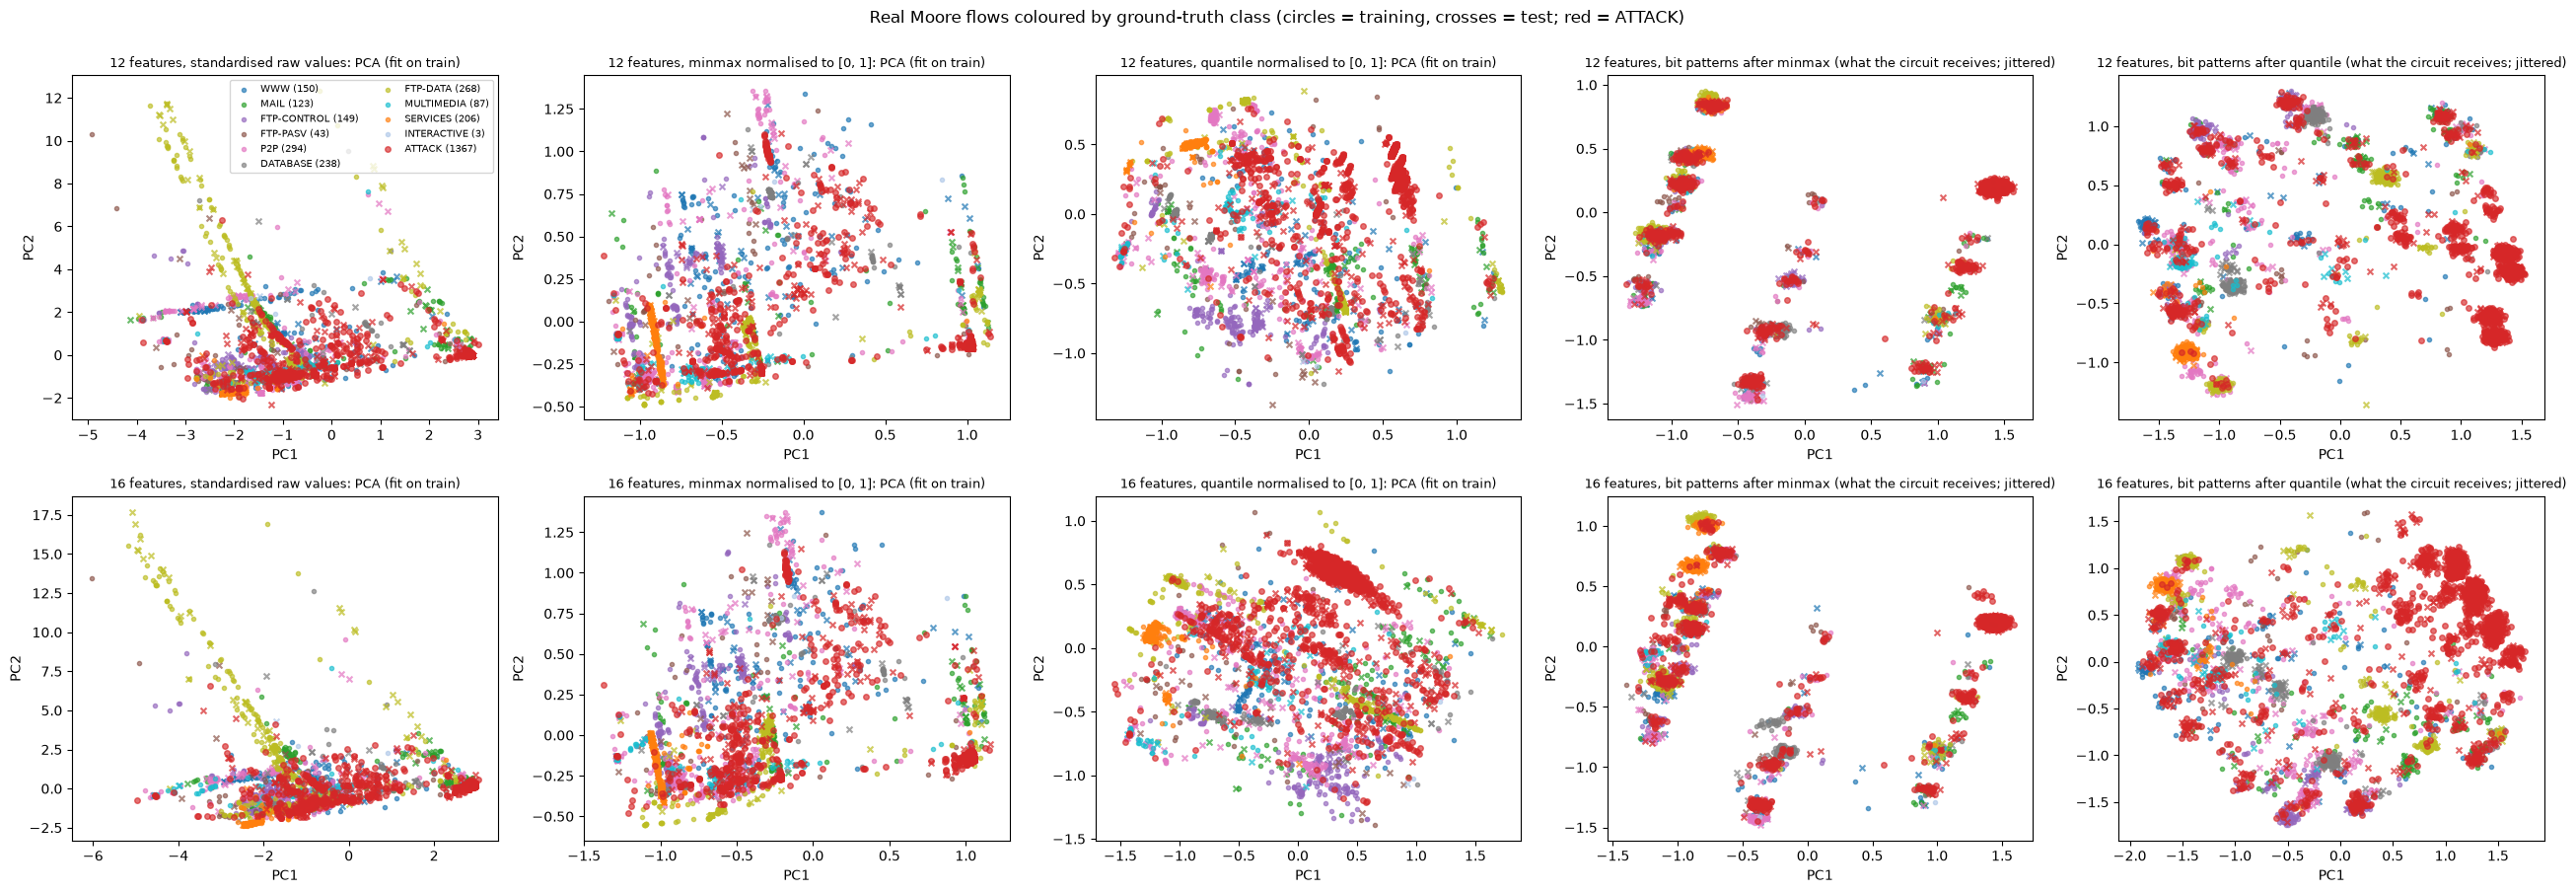

In [10]:
# Labelled projections of the real flows: standardised raw features, min-max features, quantile features (all PCA fitted on the training flows), and the binary patterns.
CLASS_ORDER = [c for c in CLASS_NAMES if c != "ATTACK"] + ["ATTACK"]      # attack drawn last so that it stays visible
def scatter_labels(ax, Ztr, Zte, title, xl="PC1", yl="PC2"):
    for c in CLASS_ORDER:
        mtr = sp["ctr"] == c
        if mtr.any(): ax.scatter(Ztr[mtr, 0], Ztr[mtr, 1], s=16 if c == "ATTACK" else 9, c=CLASS_COLORS[c], alpha=0.65, label=f"{c} ({mtr.sum()})", zorder=3 if c == "ATTACK" else 2)
        mte = sp["cte"] == c
        if mte.any(): ax.scatter(Zte[mte, 0], Zte[mte, 1], marker="x", s=18, c=CLASS_COLORS[c], alpha=0.7, zorder=3 if c == "ATTACK" else 2)
    ax.set_title(title, fontsize=9); ax.set_xlabel(xl); ax.set_ylabel(yl)

jit = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 5, figsize=(26, 9))
for r, nf in enumerate((12, 16)):
    cols = [f - 1 for f in FEATURE_SETS[nf]]; Xtr, Xte = sp["Xtr"][:, cols], sp["Xte"][:, cols]
    med = np.nanmedian(Xtr, axis=0); Xtr_i, Xte_i = np.where(np.isnan(Xtr), med, Xtr), np.where(np.isnan(Xte), med, Xte)
    sc = StandardScaler().fit(Xtr_i); pca = PCA(2, random_state=SEED).fit(sc.transform(Xtr_i))
    scatter_labels(axes[r, 0], pca.transform(sc.transform(Xtr_i)), pca.transform(sc.transform(Xte_i)), f"{nf} features, standardised raw values: PCA (fit on train)")
    for k, norm in enumerate(("minmax", "quantile")):
        A, At = prep_fit_transform(Xtr, Xte, norm); pca = PCA(2, random_state=SEED).fit(A)
        scatter_labels(axes[r, 1 + k], pca.transform(A), pca.transform(At), f"{nf} features, {norm} normalised to [0, 1]: PCA (fit on train)")
        Bt, Be = to_bits(A), to_bits(At); pca = PCA(2, random_state=SEED).fit(Bt)
        Ztr, Zte = pca.transform(Bt), pca.transform(Be); s = 0.04 * (Ztr.std(axis=0) + 1e-9)
        scatter_labels(axes[r, 3 + k], Ztr + jit.normal(0, 1, Ztr.shape) * s, Zte + jit.normal(0, 1, Zte.shape) * s,
                       f"{nf} features, bit patterns after {norm} (what the circuit receives; jittered)")
axes[0, 0].legend(fontsize=7, ncol=2)
plt.suptitle("Real Moore flows coloured by ground-truth class (circles = training, crosses = test; red = ATTACK)", y=1.0)
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

**The circuit that is executed.** Section II-D describes `KM + 1` qubits: the first `KM` qubits hold the features, the last one is the read-out
qubit, initialised in `|1>`; unitaries `U_l(theta_l)` that "act on a subset of the qubits" (Fig. 1 draws them on two qubits) are applied; the
read-out qubit is measured. The paper gives no gate list, and says it uses TensorFlow Quantum, whose QNN example is built exactly this way. We
therefore use (`# CHOICE`), for `n` = 12 or 16 features:

1. read-out qubit: `X` then `H`, i.e. the state `|->` (the paper's `|1>` read-out, rotated into the basis in which the coupling gates act);
2. data qubit `j`: an `X` gate if its bit is 1 (Section II-C);
3. for every `j`: `U_xx = exp(-i theta_j X_j X_r)` (a Qiskit `RXX(2 theta_j)`), then for every `j`: `U_zz = exp(-i phi_j Z_j Z_r)` (`RZZ(2 phi_j)`);
   so each unitary has the form `exp(i theta sigma)` with `sigma` a tensor product of Pauli operators, as eq. (3) requires;
4. `H` on the read-out qubit and a `Z` measurement: the prediction is `<Z_readout>` in [-1, 1].

Trainable parameters: `2n` angles (24 for 12 features, 32 for 16). **Why not measure `Y` as in eq. (2)?** After `XX`/`ZZ` couplings and
the read-out preparation `|1>`, `<Y>` of the read-out qubit is exactly zero for every input (checked numerically below), so the Farhi-Neven
formula cannot be taken literally with these gates; the `H` conjugation of the TFQ example makes the measured observable non-trivial.

**Exact simulation without 2^17 amplitudes.** The data qubits start in basis states and interact only with the read-out qubit, so the circuit
can be evaluated exactly: with `s_j = (-1)^{b_j}`,

`<Z_readout> = - Re  prod_j [ cos(2 phi_j) + i s_j cos(2 theta_j) sin(2 phi_j) ]`.

(Derivation: in the `X` basis of the read-out qubit the `XX` layer only rotates each data qubit by `exp(i theta_j X_j)`; the diagonal `ZZ` layer then contributes
`exp(2 i phi_j Z_j)` per qubit, and the overlap factorises over qubits.) The code below builds the **real Qiskit circuit**, asserts that this
closed form and its analytic gradient agree with it to machine precision, and the closed form is then used for all training. The product structure
also shows that this QNN is *classically* easy to simulate; it is a teaching model, not a quantum advantage.

In [11]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector, SparsePauliOp

def qnn_circuit(bits, theta, phi):
    """The circuit of the paper (Fig. 1) in the form of the Google TensorFlow Quantum QNN example the paper builds on:
    n = KM data qubits + 1 readout qubit (index n). Readout is prepared in |1> and rotated by a Hadamard; data qubit j gets an
    X gate when its bit is 1 (Section II-C). Every data qubit is then coupled to the readout qubit by the two-qubit unitaries
    U_xx = exp(-i theta_j X_j X_r) and afterwards U_zz = exp(-i phi_j Z_j Z_r) (each unitary acts on two qubits, as in Fig. 1);
    a final Hadamard on the readout qubit and a Z measurement give the prediction <Z_readout> in [-1, 1].
    `bits` is a 0/1 vector; theta/phi are numbers or Qiskit Parameters.
    # CHOICE: the paper does not list the gates; XX and ZZ couplings with H-conjugated readout are the TFQ example's choice
    (measuring Pauli-Y after XX/ZZ gates, as in Farhi-Neven's formula, gives <Y> = 0 for every input, checked numerically)."""
    n = len(bits)
    qc = QuantumCircuit(n + 1, name=f"QNN-{n}")
    qc.x(n); qc.h(n)                                  # readout |1> then Hadamard -> |->
    for j in range(n):
        if bits[j] == 1: qc.x(j)                      # classical bit -> basis state (Section II-C)
    qc.barrier()
    for j in range(n): qc.rxx(2 * theta[j], j, n)     # exp(-i theta XX) = RXX(2 theta)
    for j in range(n): qc.rzz(2 * phi[j], j, n)       # exp(-i phi ZZ)   = RZZ(2 phi)
    qc.barrier()
    qc.h(n)
    return qc

def qiskit_expZ(bits, theta, phi):
    """<Z> on the readout qubit by exact state-vector simulation of the real Qiskit circuit."""
    n = len(bits)
    sv = Statevector(qnn_circuit(bits, theta, phi))
    return float(sv.expectation_value(SparsePauliOp.from_sparse_list([("Z", [n], 1.0)], num_qubits=n + 1)).real)

def expZ(bits, theta, phi):
    """Exact <Z_readout> for a batch of bit strings and K parameter sets without building 2^(n+1) amplitudes.
    bits: (B, n) of 0/1; theta, phi: (K, n) -> (K, B). Closed form (derived in the text above):
        <Z> = - Re  prod_j [ cos(2 phi_j) + i (-1)^{b_j} cos(2 theta_j) sin(2 phi_j) ]."""
    b = np.asarray(bits)[None]; th = np.asarray(theta)[:, None, :]; ph = np.asarray(phi)[:, None, :]
    m = np.cos(2 * ph) + 1j * np.where(b == 0, 1.0, -1.0) * np.cos(2 * th) * np.sin(2 * ph)
    return -np.prod(m, axis=2).real
def loss_and_grad_shift(bits, y_pm, theta, phi):
    """Sample loss of eq. (2), loss = 1 - l(q) <Y>, averaged over a batch, and its exact gradient by the parameter-shift rule
    (each parameter sits in one gate exp(-i t G) with G^2 = 1, so d f/d t = f(t + pi/4) - f(t - pi/4))."""
    n = theta.shape[0]; sh = np.pi / 4; K = 4 * n
    T = np.tile(theta, (K, 1)); P = np.tile(phi, (K, 1))
    for j in range(n):
        T[4 * j, j] += sh; T[4 * j + 1, j] -= sh; P[4 * j + 2, j] += sh; P[4 * j + 3, j] -= sh
    f = expZ(bits, T, P)
    df = np.empty((2 * n, bits.shape[0]))
    for j in range(n):
        df[j] = f[4 * j] - f[4 * j + 1]; df[n + j] = f[4 * j + 2] - f[4 * j + 3]
    y0 = expZ(bits, theta[None], phi[None])[0]
    return float(np.mean(1 - y_pm * y0)), -(df * y_pm[None]).mean(axis=1)



def loss_and_grad(bits, y_pm, theta, phi):
    """Same loss and gradient in closed form (prefix/suffix products of the per-qubit factors m_j); used for training because it
    is about 100x faster than the parameter-shift version. Checked against it (and against finite differences of the Qiskit circuit)."""
    b = np.asarray(bits); s = np.where(b == 0, 1.0, -1.0)
    c2t, s2t, c2p, s2p = np.cos(2 * theta), np.sin(2 * theta), np.cos(2 * phi), np.sin(2 * phi)
    m = c2p + 1j * s * c2t * s2p                                  # (B, n)
    B, n = m.shape
    pre = np.ones((B, n), dtype=complex); suf = np.ones((B, n), dtype=complex)
    for j in range(1, n): pre[:, j] = pre[:, j - 1] * m[:, j - 1]
    for j in range(n - 2, -1, -1): suf[:, j] = suf[:, j + 1] * m[:, j + 1]
    rest = pre * suf                                              # product of all factors except j
    P = pre[:, -1] * m[:, -1]                                     # full product; <Z> = -Re P
    dm_dth = -2j * s * s2t * s2p
    dm_dph = -2 * s2p + 2j * s * c2t * c2p
    y = np.asarray(y_pm)[:, None]
    g_th = (y * (rest * dm_dth).real).mean(axis=0); g_ph = (y * (rest * dm_dph).real).mean(axis=0)
    return float(np.mean(1 + y_pm * P.real)), np.concatenate([g_th, g_ph])

12 features: qubits = 13 (12 data + 1 read-out) | depth = 27 | trainable parameters = 24 | gates = {'rxx': 12, 'rzz': 12, 'x': 7, 'h': 2, 'barrier': 2}
   bits of the drawn ATTACK flow (feature order [1, 2, 15, 22, 29, 81, 158, 165, 173, 194, 230, 240]): 011110000011


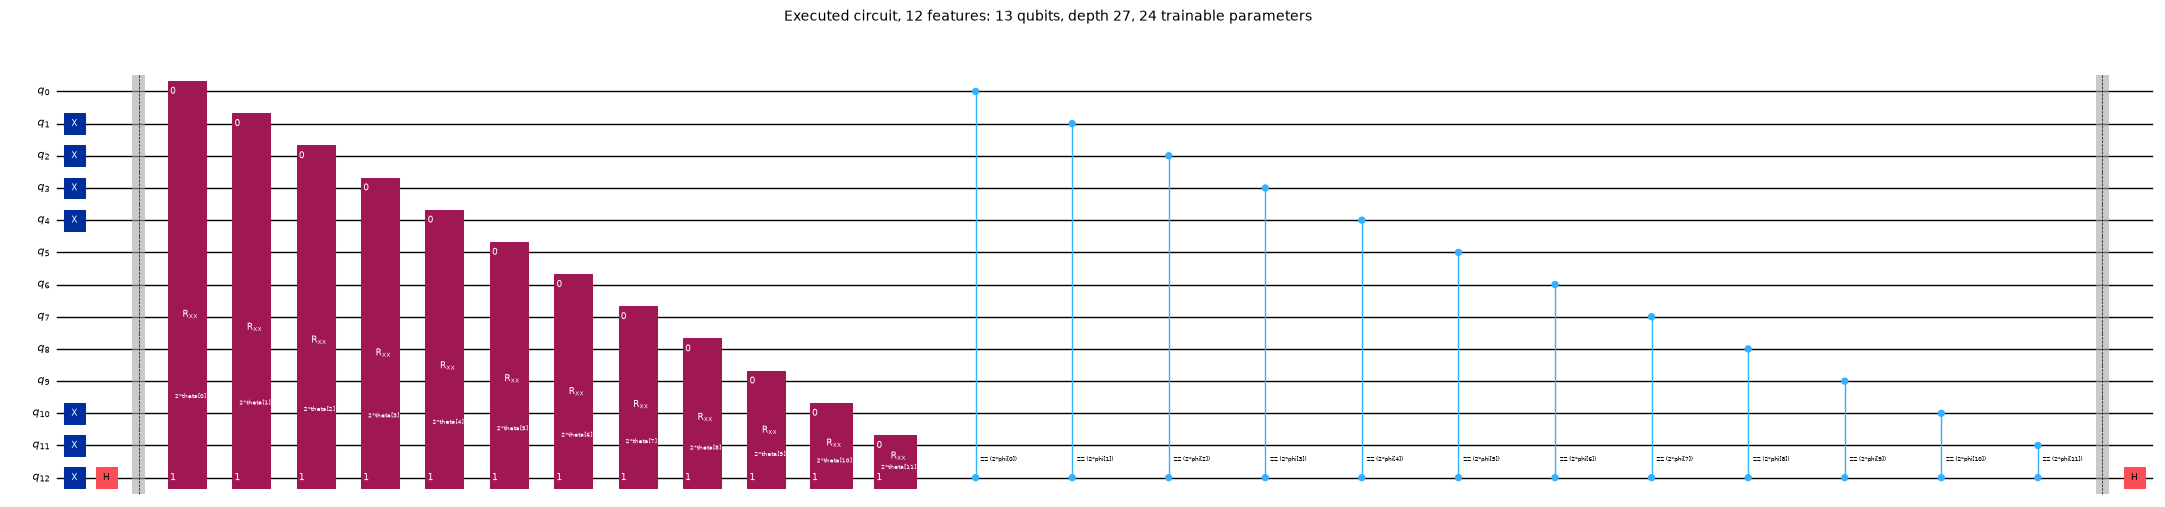

16 features: qubits = 17 (16 data + 1 read-out) | depth = 35 | trainable parameters = 32 | gates = {'rxx': 16, 'rzz': 16, 'x': 9, 'h': 2, 'barrier': 2}
   bits of the drawn ATTACK flow (feature order [1, 2, 15, 22, 29, 81, 158, 165, 173, 194, 230, 231, 232, 240, 241, 242]): 0111100000101101


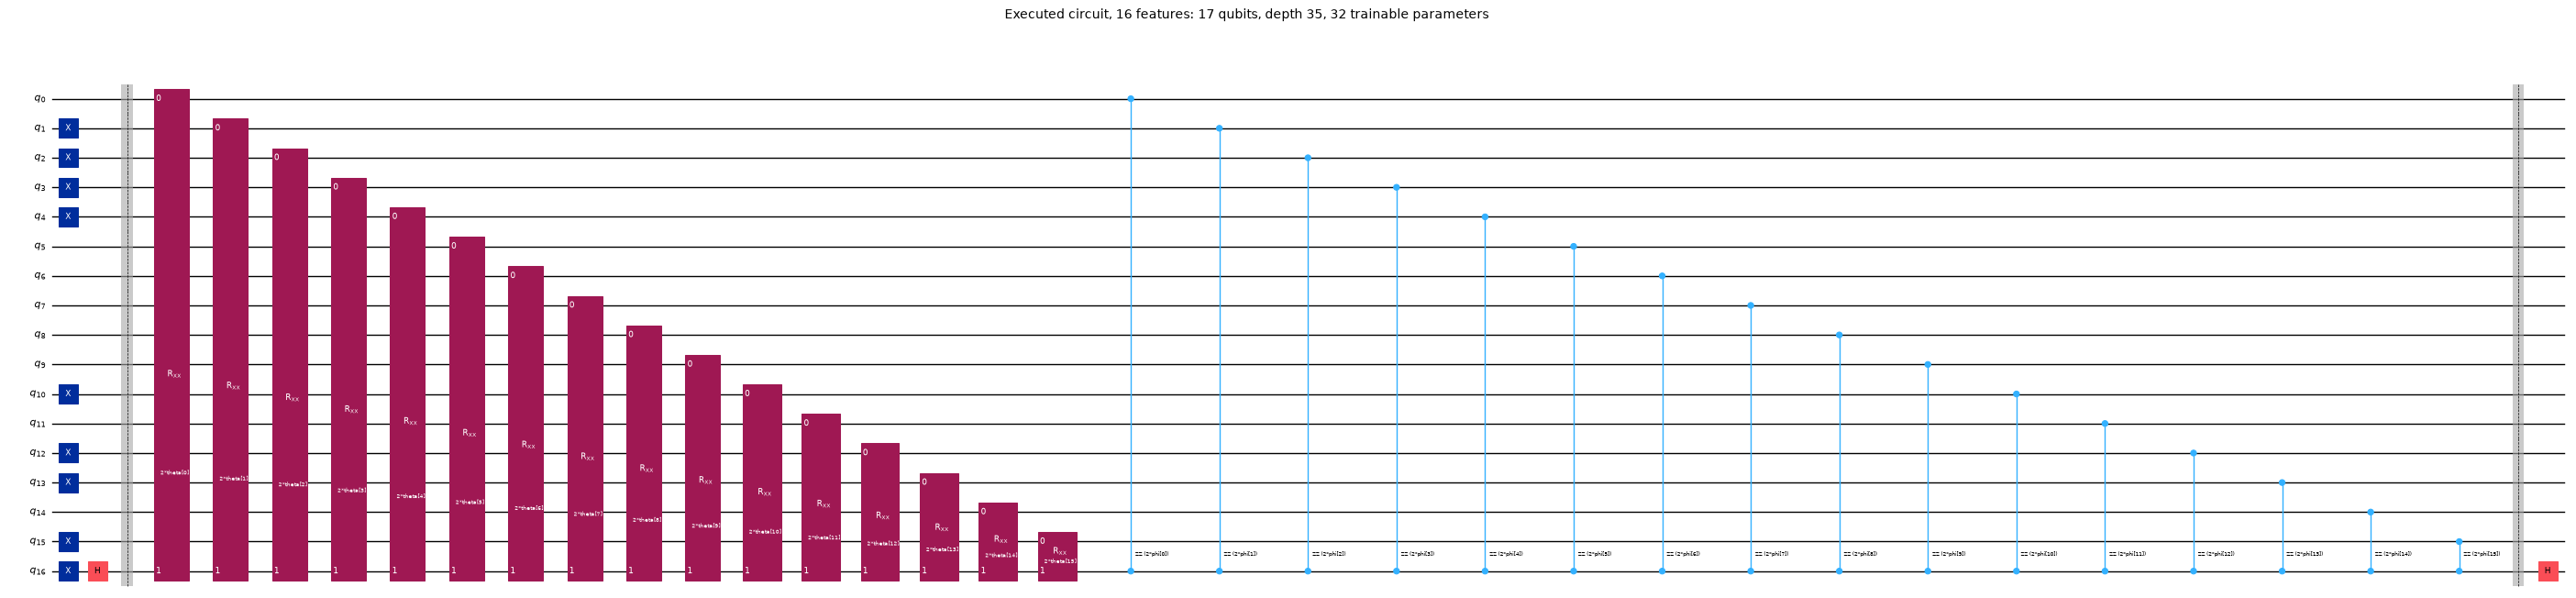

In [12]:
# Draw the circuits that are executed: one per architecture (12 features -> 13 qubits, 16 features -> 17 qubits), for a real training flow.
from qiskit.circuit import ParameterVector
CIRC = {}
for nf in (12, 16):
    cols = [f - 1 for f in FEATURE_SETS[nf]]
    A, _ = prep_fit_transform(sp["Xtr"][:, cols], sp["Xte"][:, cols], "quantile")
    i_att = int(np.where(sp["ytr"])[0][0]); example_bits = to_bits(A)[i_att]
    th, ph = ParameterVector("theta", nf), ParameterVector("phi", nf)
    qc = qnn_circuit(example_bits, th, ph); CIRC[nf] = qc
    print(f"{nf} features: qubits = {qc.num_qubits} ({nf} data + 1 read-out) | depth = {qc.depth()} | trainable parameters = {qc.num_parameters} | gates = {dict(qc.count_ops())}")
    print(f"   bits of the drawn ATTACK flow (feature order {FEATURE_SETS[nf]}): {''.join(map(str, example_bits))}")
    fig = qc.draw("mpl", fold=-1, scale=0.5, idle_wires=True)
    fig.suptitle(f"Executed circuit, {nf} features: {qc.num_qubits} qubits, depth {qc.depth()}, {qc.num_parameters} trainable parameters", fontsize=10)
    display(fig); plt.close(fig)

In [13]:
# Equivalence tests: the closed form used for training must equal the real Qiskit circuit (values and gradients).
rng_eq = np.random.default_rng(SEED)
for nf in (12, 16):
    th_, ph_ = rng_eq.uniform(-2, 2, nf), rng_eq.uniform(-2, 2, nf); Bs = rng_eq.integers(0, 2, (8, nf))
    fast = expZ(Bs, th_[None], ph_[None])[0]; ref = np.array([qiskit_expZ(b, th_, ph_) for b in Bs])
    assert np.allclose(fast, ref, atol=1e-10), "closed form differs from the Qiskit circuit"
    print(f"{nf} features: max |closed form - Qiskit state vector| over 8 random flows = {np.abs(fast - ref).max():.2e}")

nf = 12; th_, ph_ = rng_eq.uniform(-2, 2, nf), rng_eq.uniform(-2, 2, nf); Bs = rng_eq.integers(0, 2, (4, nf)); ys_ = np.array([1.0, -1.0, -1.0, 1.0])
loss_a, g_a = loss_and_grad(Bs, ys_, th_, ph_); loss_s, g_s = loss_and_grad_shift(Bs, ys_, th_, ph_)
def loss_qiskit(t, p): return float(np.mean([1 - y * qiskit_expZ(b, t, p) for b, y in zip(Bs, ys_)]))
eps = 1e-5; g_fd = np.zeros(2 * nf)
for j in range(nf):
    t1, t2 = th_.copy(), th_.copy(); t1[j] += eps; t2[j] -= eps; g_fd[j] = (loss_qiskit(t1, ph_) - loss_qiskit(t2, ph_)) / (2 * eps)
    p1, p2 = ph_.copy(), ph_.copy(); p1[j] += eps; p2[j] -= eps; g_fd[nf + j] = (loss_qiskit(th_, p1) - loss_qiskit(th_, p2)) / (2 * eps)
assert abs(loss_a - loss_qiskit(th_, ph_)) < 1e-10 and np.allclose(g_a, g_s, atol=1e-10) and np.allclose(g_a, g_fd, atol=1e-6)
print(f"loss: closed form {loss_a:.10f} = Qiskit {loss_qiskit(th_, ph_):.10f}; max |analytic - parameter-shift| = {np.abs(g_a - g_s).max():.1e}; max |analytic - finite differences of the Qiskit circuit| = {np.abs(g_a - g_fd).max():.1e}")

# Why Pauli-Y (eq. 2 taken literally) does not work with these gates: <Y_readout> of the same couplings, read-out prepared in |1> without the Hadamards.
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, SparsePauliOp
worst = 0.0
for _ in range(20):
    nn = 6; bb = rng_eq.integers(0, 2, nn); t_, p_ = rng_eq.uniform(-2, 2, nn), rng_eq.uniform(-2, 2, nn)
    q = QuantumCircuit(nn + 1); q.x(nn)
    for j in range(nn):
        if bb[j]: q.x(j)
    for j in range(nn): q.rxx(2 * t_[j], j, nn)
    for j in range(nn): q.rzz(2 * p_[j], j, nn)
    worst = max(worst, abs(Statevector(q).expectation_value(SparsePauliOp.from_sparse_list([("Y", [nn], 1.0)], num_qubits=nn + 1)).real))
print(f"largest |<Y_readout>| over 20 random circuits with the readout in |1>: {worst:.1e}  (identically zero, so the H-conjugated Z read-out is used)")

12 features: max |closed form - Qiskit state vector| over 8 random flows = 2.66e-15


16 features: max |closed form - Qiskit state vector| over 8 random flows = 3.39e-15


loss: closed form 1.0472084845 = Qiskit 1.0472084845; max |analytic - parameter-shift| = 6.2e-17; max |analytic - finite differences of the Qiskit circuit| = 3.6e-11


largest |<Y_readout>| over 20 random circuits with the readout in |1>: 0.0e+00  (identically zero, so the H-conjugated Z read-out is used)


## 3. Training and choosing the preprocessing on a validation split

Training minimises the paper's sample loss `1 - l(q) <Z_readout>` averaged over a mini-batch (`l = +1` attack, `-1` otherwise) with Adam.
The gradient is the analytic one verified above. `train_qnn` records the loss and accuracy after every epoch, and the size of every gradient
step, which is what the paper's "no gradient explosion" claim is about. `run_one` fits normalisation, binarisation, conflict handling and
the QNN on the training flows (or on 80 % of them for validation) and scores the held-out flows.

In [14]:
def train_qnn(B, y, seed, epochs):
    """Mini-batch Adam on the paper's sample loss  loss = 1 - l(q) <Z_readout>  (labels l = +1 attack, -1 non-attack).
    Returns the 2n angles and a history: per-epoch loss/accuracy on the training flows, per-step batch loss and gradient size."""
    n = B.shape[1]; rng = np.random.default_rng(seed)
    p = rng.normal(0.0, INIT_STD, 2 * n)                                   # CHOICE: initial angles ~ N(0, INIT_STD)
    ys = np.where(y, 1.0, -1.0)
    m1 = np.zeros_like(p); m2 = np.zeros_like(p); t = 0
    hist = dict(epoch_loss=[], epoch_acc=[], step_loss=[], step_gmax=[], step_gnorm=[], nan=False)
    if len(y) == 0:
        return p, hist
    for ep in range(epochs):
        order = rng.permutation(len(y))
        for i in range(0, len(y), BATCH_SIZE):
            bi = order[i:i + BATCH_SIZE]
            loss, g = loss_and_grad(B[bi], ys[bi], p[:n], p[n:])
            t += 1; m1 = 0.9 * m1 + 0.1 * g; m2 = 0.999 * m2 + 0.001 * g * g
            p = p - LR * (m1 / (1 - 0.9 ** t)) / (np.sqrt(m2 / (1 - 0.999 ** t)) + 1e-8)
            hist["step_loss"].append(loss); hist["step_gmax"].append(float(np.abs(g).max())); hist["step_gnorm"].append(float(np.linalg.norm(g)))
        f = expZ(B, p[None, :n], p[None, n:])[0]
        hist["epoch_loss"].append(float(np.mean(1 - ys * f))); hist["epoch_acc"].append(float(np.mean((f > 0) == y)))
    hist["nan"] = bool(np.isnan(hist["step_loss"]).any() or np.isnan(p).any())
    return p, hist

def run_one(split, nf, norm, conflict, seed, epochs, validate=False, keep_arrays=False):
    """Train on the training flows (or on 80 % of them when validate=True) and evaluate on the test flows (or the held-out 20 %)."""
    cols = [f - 1 for f in FEATURE_SETS[nf]]
    Xall, yall = split["Xtr"][:, cols], split["ytr"]
    if validate:
        ia, ib = train_test_split(np.arange(len(yall)), test_size=VAL_FRACTION, stratify=yall, random_state=seed)
        Xa, ya, Xb, yb = Xall[ia], yall[ia], Xall[ib], yall[ib]
    else:
        Xa, ya, Xb, yb = Xall, yall, split["Xte"][:, cols], split["yte"]
    A, Ab = prep_fit_transform(Xa, Xb, norm)
    Ba, Bb = to_bits(A), to_bits(Ab)
    Bk, yk, n_conf = resolve_conflicts(Ba, ya, conflict)
    t0 = time.time(); p, hist = train_qnn(Bk, yk, seed, epochs); secs = time.time() - t0
    f = expZ(Bb, p[None, :nf], p[None, nf:])[0]
    out = dict(nf=nf, norm=norm, conflict=conflict, seed=seed, n_fit=len(ya), n_kept=len(yk), n_conflict_rows=n_conf, seconds=secs,
               hist=hist, params=p, **attack_metrics(yb, f > 0))
    if keep_arrays:
        out.update(A=A, Ab=Ab, Ba=Ba, Bb=Bb, Bk=Bk, yk=yk, ya=ya, yb=yb, f=f, Xa=Xa, Xb=Xb)
    return out

In [15]:
# Choose the preprocessing (normalisation x conflict handling) per feature set on a validation split of the TRAINING flows only.
SEL_ROWS = []
t0 = time.time()
for nf in (12, 16):
    for norm, conflict in GRID:
        for k in range(N_SEL_SEEDS):
            r = run_one(get_split(SEED + k), nf, norm, conflict, SEED + k, EPOCHS, validate=True)
            SEL_ROWS.append(dict(features=nf, normalisation=norm, conflicts=conflict, seed=SEED + k, val_f1=r["f1"], val_precision=r["precision"],
                                 val_recall=r["recall"], flows_kept=r["n_kept"]))
sel = pd.DataFrame(SEL_ROWS)
sel_mean = sel.groupby(["features", "normalisation", "conflicts"], sort=False)[["val_f1", "val_precision", "val_recall", "flows_kept"]].mean().round(1)
BEST = {}
for nf in (12, 16):
    sub = sel_mean.loc[nf]; (bn, bc) = sub["val_f1"].idxmax(); BEST[nf] = (bn, bc)
sel_mean["selected"] = [(n_, c_) == BEST[f_] for (f_, n_, c_) in sel_mean.index]
display(sel_mean)
print("selected on validation F1 (training flows only):", BEST, f"({time.time() - t0:.0f} s)")

val_f1  val_precision  val_recall  flows_kept  selected
features normalisation conflicts                                                         
12       minmax        drop_all      0.0            0.0         0.0       176.7     False
                       majority     79.0           87.1        72.3      1985.7     False
                       none         79.0           87.1        72.3      2342.0     False
         quantile      drop_all     78.5           73.9        83.7      1129.0     False
                       majority     81.9           79.7        84.3      2129.0      True
                       none         81.2           82.0        80.4      2342.0     False
16       minmax        drop_all      0.2           11.1         0.1       259.7     False
                       majority     79.5           88.1        72.4      2027.7     False
                       none         79.5           88.1        72.4      2342.0     False
         quantile      drop_all     81.8           80.8        82.8      1456.3      True
                       majority     81.4           83.9        79.2      2152.0     False
                       none         81.8           84.6        79.2      2342.0     False

selected on validation F1 (training flows only): {12: ('quantile', 'majority'), 16: ('quantile', 'drop_all')} (180 s)


## 4. Final runs on the test flows: Fig. 3 and Fig. 4 re-drawn

For each feature set the selected preprocessing is trained on the full training draw and evaluated on the test draw, for `N_SEEDS` different
random draws of the flows and initial angles. All six preprocessing combinations are also scored on the test flows for the ablation table (section 6).

In [16]:
GRID_ROWS, BEST_RUNS = [], {12: [], 16: []}
t0 = time.time()
for nf in (12, 16):
    for norm, conflict in GRID:
        for k in range(N_SEEDS):
            is_best = (norm, conflict) == BEST[nf]
            r = run_one(get_split(SEED + k), nf, norm, conflict, SEED + k, EPOCHS, keep_arrays=is_best)
            GRID_ROWS.append(dict(features=nf, normalisation=norm, conflicts=conflict, seed=SEED + k, selected=is_best,
                                  **{kk: r[kk] for kk in ("accuracy", "precision", "recall", "f1", "tnr", "tn", "fp", "fn", "tp", "n_kept", "seconds")}))
            if is_best: BEST_RUNS[nf].append(r)
GRID_DF = pd.DataFrame(GRID_ROWS)
print(f"{len(GRID_DF)} trainings finished in {time.time() - t0:.0f} s")
final = pd.DataFrame([{k: v for k, v in dict(features=nf, seed=r["seed"], flows_kept=r["n_kept"], accuracy=r["accuracy"], precision=r["precision"], recall_attack=r["recall"],
                                              recall_normal=r["tnr"], f1=r["f1"], seconds=r["seconds"], tn=r["tn"], fp=r["fp"], fn=r["fn"], tp=r["tp"]).items()}
                      for nf in (12, 16) for r in BEST_RUNS[nf]])
display(final.round(2))
SUMMARY = final.groupby("features")[["accuracy", "precision", "recall_attack", "recall_normal", "f1"]].agg(["mean", "std"]).round(2)
display(SUMMARY)

60 trainings finished in 365 s


,features,seed,flows_kept,accuracy,precision,recall_attack,recall_normal,f1,seconds,tn,fp,fn,tp
0,12,42,2669,80.79,86.80,69.48,90.72,77.18,3.47,440,45,130,296
1,12,43,2608,80.46,81.47,75.35,84.95,78.29,2.47,412,73,105,321
2,12,44,2675,79.80,78.01,79.11,80.41,78.55,2.46,390,95,89,337
3,12,45,2668,80.35,79.06,78.87,81.65,78.97,5.76,396,89,90,336
4,12,46,2664,79.36,78.20,77.46,81.03,77.83,2.78,393,92,96,330
5,16,42,1740,84.19,86.72,78.17,89.48,82.22,9.21,434,51,93,333
6,16,43,1781,81.78,80.37,80.75,82.68,80.56,5.28,401,84,82,344
7,16,44,1806,84.41,85.68,80.05,88.25,82.77,9.74,428,57,85,341
8,16,45,1767,78.59,80.00,72.30,84.12,75.96,8.59,408,77,118,308
9,16,46,1770,81.56,82.25,77.23,85.36,79.66,7.37,414,71,97,329


accuracy       precision       recall_attack       recall_normal           f1      
             mean   std      mean   std          mean   std          mean   std   mean   std
features                                                                                    
12          80.15  0.57     80.71  3.68         76.06  3.97         83.75  4.27  78.17  0.69
16          82.11  2.37     83.00  3.06         77.70  3.33         85.98  2.83  80.23  2.70

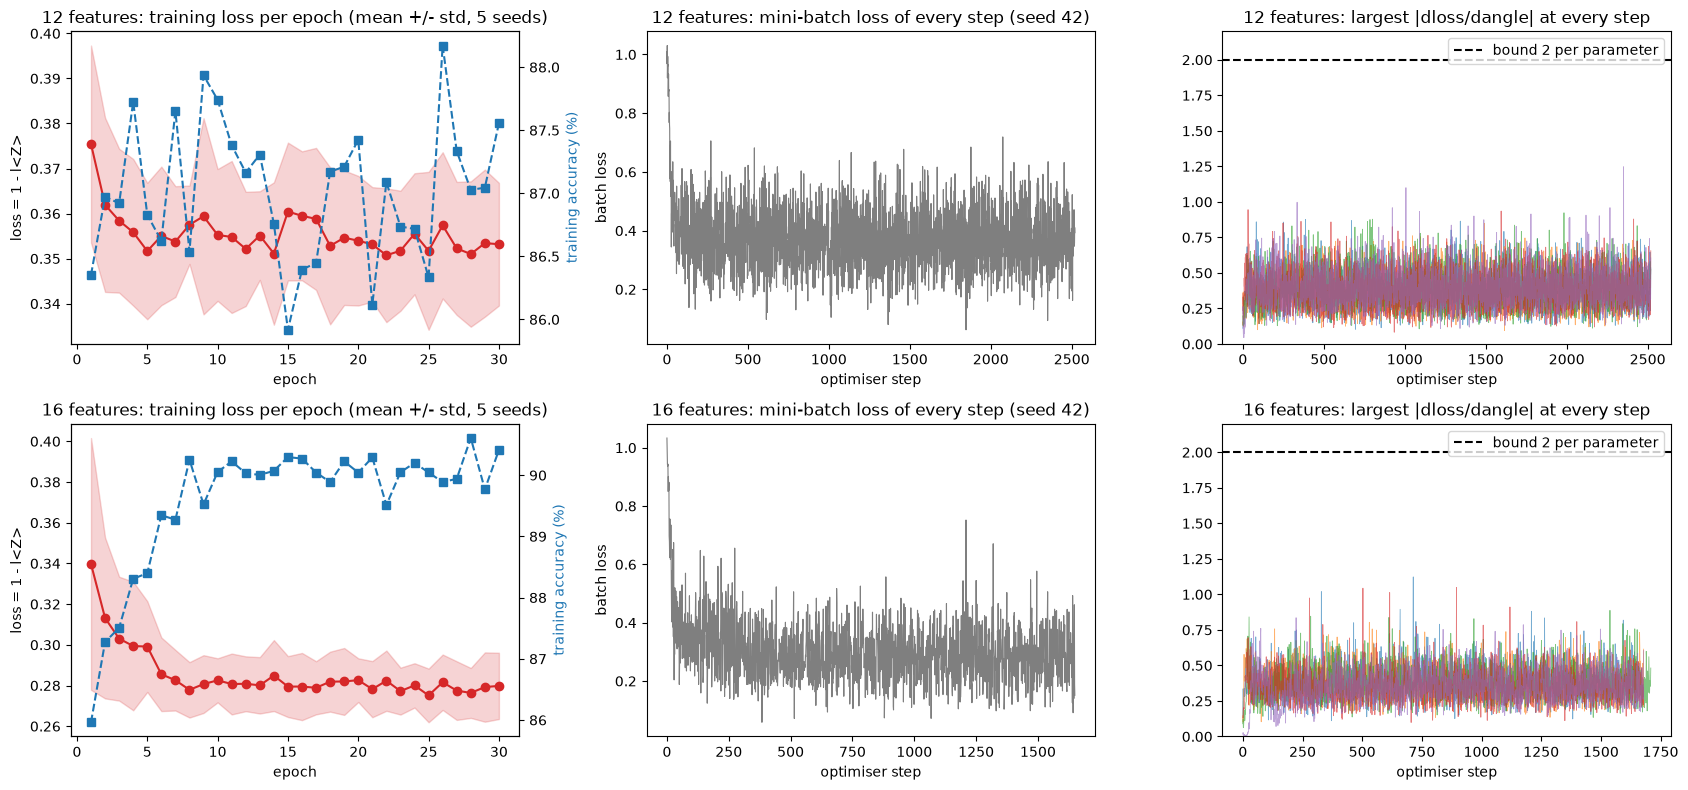

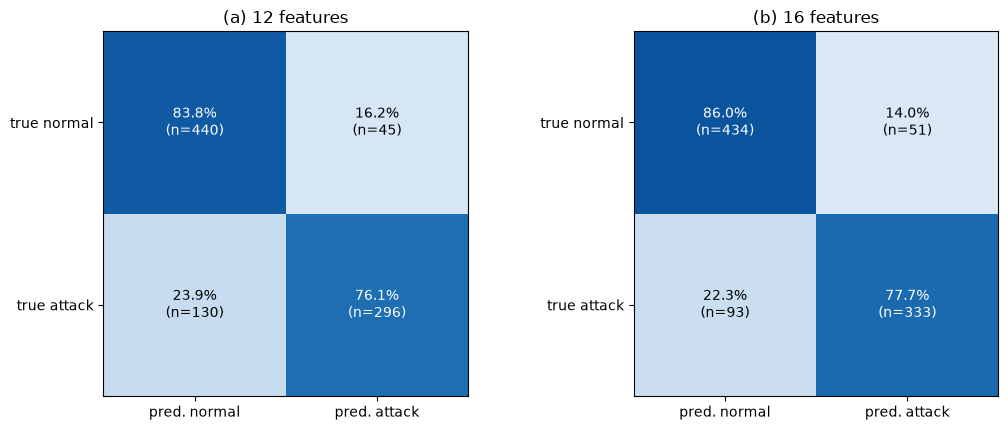

In [17]:
# Fig. 3 re-drawn: loss and accuracy during training (mean +/- std over seeds), batch-level loss of one run, and the size of every gradient step.
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for row, nf in enumerate((12, 16)):
    runs = BEST_RUNS[nf]; L = np.array([r["hist"]["epoch_loss"] for r in runs]); Ac = 100 * np.array([r["hist"]["epoch_acc"] for r in runs]); ep = np.arange(1, L.shape[1] + 1)
    axes[row, 0].plot(ep, L.mean(0), "o-", color="tab:red"); axes[row, 0].fill_between(ep, L.mean(0) - L.std(0), L.mean(0) + L.std(0), color="tab:red", alpha=0.2)
    axes[row, 0].set_title(f"{nf} features: training loss per epoch (mean +/- std, {len(runs)} seeds)"); axes[row, 0].set_xlabel("epoch"); axes[row, 0].set_ylabel("loss = 1 - l<Z>")
    ax2 = axes[row, 0].twinx(); ax2.plot(ep, Ac.mean(0), "s--", color="tab:blue"); ax2.set_ylabel("training accuracy (%)", color="tab:blue")
    h = runs[0]["hist"]; axes[row, 1].plot(h["step_loss"], lw=0.8, color="tab:gray"); axes[row, 1].set_title(f"{nf} features: mini-batch loss of every step (seed {runs[0]['seed']})")
    axes[row, 1].set_xlabel("optimiser step"); axes[row, 1].set_ylabel("batch loss")
    for r in runs: axes[row, 2].plot(r["hist"]["step_gmax"], lw=0.6, alpha=0.6)
    axes[row, 2].axhline(2.0, color="k", ls="--", label="bound 2 per parameter"); axes[row, 2].set_ylim(0, 2.2)
    axes[row, 2].set_title(f"{nf} features: largest |dloss/dangle| at every step"); axes[row, 2].set_xlabel("optimiser step"); axes[row, 2].legend()
plt.tight_layout(); plt.show()

# Fig. 4 re-drawn: confusion matrices (row-normalised, mean over seeds; counts of the first seed in the annotation).
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, nf, tag in zip(axes, (12, 16), ("(a)", "(b)")):
    cms = np.array([[[r["tn"], r["fp"]], [r["fn"], r["tp"]]] for r in BEST_RUNS[nf]], dtype=float)
    pct = (cms / cms.sum(axis=2, keepdims=True)).mean(0) * 100; c0 = cms[0].astype(int)
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=100)
    for i in range(2):
        for j in range(2): ax.text(j, i, f"{pct[i, j]:.1f}%\n(n={c0[i, j]})", ha="center", va="center", color="white" if pct[i, j] > 50 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["pred. normal", "pred. attack"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["true normal", "true attack"])
    ax.set_title(f"{tag} {nf} features")
plt.tight_layout(); plt.show()

## 5. Classical baselines on the same inputs

The paper compares only qualitatively with "a classical neural network". We train, on **exactly the same inputs** as the quantum model
(the bits left after conflict handling, same flows, same seeds): a random forest, an RBF-kernel SVM and logistic regression on the bits; and, to see
what the binarisation costs, a random forest, an SVM and a small MLP on the same 12/16 features **before** binarisation (normalised values), and a random
forest on **all 248** features (training median fills missing values).

In [18]:
def baseline_rows(nf, r):
    sp_ = get_split(r["seed"]); out = []
    def add(name, model, Xa, ya, Xb):
        t0 = time.time(); model.fit(Xa, ya); pred = model.predict(Xb).astype(bool)
        out.append(dict(features=nf, seed=r["seed"], model=name, seconds=time.time() - t0, **attack_metrics(sp_["yte"], pred)))
    Bk, yk, Bb = r["Bk"], r["yk"], r["Bb"]
    add("RF on the bits", RandomForestClassifier(100, random_state=r["seed"], n_jobs=1), Bk, yk, Bb)
    add("SVC(rbf) on the bits", SVC(kernel="rbf", random_state=r["seed"]), Bk, yk, Bb)
    add("LogReg on the bits", LogisticRegression(max_iter=2000), Bk, yk, Bb)
    add("RF on normalised features", RandomForestClassifier(100, random_state=r["seed"], n_jobs=1), r["A"], r["ya"], r["Ab"])
    add("SVC(rbf) on normalised features", SVC(kernel="rbf", random_state=r["seed"]), r["A"], r["ya"], r["Ab"])
    add("MLP on normalised features", MLPClassifier((32, 16), max_iter=300, early_stopping=True, random_state=r["seed"]), r["A"], r["ya"], r["Ab"])
    med = np.nanmedian(sp_["Xtr"], axis=0); med = np.where(np.isnan(med), 0, med)
    Xa, Xb = np.where(np.isnan(sp_["Xtr"]), med, sp_["Xtr"]), np.where(np.isnan(sp_["Xte"]), med, sp_["Xte"])
    if nf == 12: add("RF on all 248 features", RandomForestClassifier(100, random_state=r["seed"], n_jobs=1), Xa, sp_["ytr"], Xb)
    return out

BASE = []
for nf in (12, 16):
    for r in BEST_RUNS[nf]: BASE += baseline_rows(nf, r)
BASE = pd.DataFrame(BASE)
qnn = pd.DataFrame([dict(features=nf, seed=r["seed"], model="QNN (this notebook)", **{k: r[k] for k in ("accuracy", "precision", "recall", "f1", "tnr", "seconds")}) for nf in (12, 16) for r in BEST_RUNS[nf]])
ALLM = pd.concat([qnn, BASE], ignore_index=True)
tab = ALLM.groupby(["features", "model"], sort=False)[["accuracy", "precision", "recall", "f1", "tnr", "seconds"]].agg(["mean", "std"]).round(1)
display(tab)

accuracy      precision      recall         f1        tnr      seconds     
                                             mean  std      mean  std   mean  std  mean  std  mean  std    mean  std
features model                                                                                                      
12       QNN (this notebook)                 80.2  0.6      80.7  3.7   76.1  4.0  78.2  0.7  83.8  4.3     3.4  1.4
16       QNN (this notebook)                 82.1  2.4      83.0  3.1   77.7  3.3  80.2  2.7  86.0  2.8     8.0  1.8
12       RF on the bits                      87.8  1.9      86.5  3.4   87.8  1.7  87.1  1.9  87.8  3.4     2.0  1.9
         SVC(rbf) on the bits                87.9  2.1      86.2  3.5   88.5  1.4  87.3  2.1  87.4  3.5     0.2  0.1
         LogReg on the bits                  82.1  0.9      84.4  1.4   75.8  1.9  79.8  1.2  87.7  1.3     0.2  0.2
         RF on normalised features           94.6  0.4      95.9  0.6   92.3  0.9  94.1  0.5  96.5  0.6     2.5  1.9
         SVC(rbf) on normalised features     93.3  0.3      93.8  0.6   91.7  0.9  92.7  0.3  94.6  0.6     0.9  0.9
         MLP on normalised features          90.9  2.3      92.8  1.9   87.3  3.6  89.9  2.7  94.1  1.5     3.7  2.3
         RF on all 248 features              95.4  0.5      96.2  0.6   93.8  0.6  95.0  0.5  96.8  0.5     5.1  1.8
16       RF on the bits                      88.5  0.9      96.4  0.7   78.4  2.1  86.4  1.2  97.4  0.5     2.6  2.0
         SVC(rbf) on the bits                89.2  0.7      96.4  0.9   79.9  1.9  87.4  1.0  97.4  0.7     0.5  0.4
         LogReg on the bits                  82.5  0.6      87.1  0.7   73.4  0.9  79.7  0.7  90.5  0.6     0.1  0.0
         RF on normalised features           94.7  0.5      96.3  0.9   92.1  1.1  94.2  0.5  96.9  0.8     3.9  2.3
         SVC(rbf) on normalised features     93.0  0.2      94.4  0.5   90.3  0.1  92.3  0.2  95.3  0.4     2.6  0.6
         MLP on normalised features          91.6  1.1      94.3  0.8   87.3  1.9  90.7  1.3  95.4  0.6     8.1  4.5

## 6. Ablation: the two preprocessing choices the paper leaves open

flows_kept  precision  precision_std  recall_attack    f1  f1_std  recall_normal  selected
features normalisation conflicts                                                                                            
12       minmax        drop_all        218.2       40.0           54.8            0.2   0.5     0.7          100.0     False
                       majority       2494.8       84.8            2.8           68.7  75.9     1.0           89.1     False
                       none           2928.0       84.8            2.9           68.7  75.9     1.1           89.1     False
         quantile      drop_all       1335.8       70.4            1.7           78.4  74.1     1.2           71.0     False
                       majority       2656.8       80.7            3.7           76.1  78.2     0.7           83.8      True
                       none           2928.0       85.0            2.6           75.2  79.7     3.1           88.3     False
16       minmax        drop_all        306.2       40.0           54.8            0.1   0.3     0.4          100.0     False
                       majority       2538.4       86.3            2.6           69.0  76.7     1.2           90.4     False
                       none           2928.0       86.3            2.6           69.1  76.7     1.2           90.3     False
         quantile      drop_all       1772.8       83.0            3.1           77.7  80.2     2.7           86.0      True
                       majority       2689.4       87.3            2.2           72.5  79.2     2.1           90.7     False
                       none           2928.0       88.5            1.6           73.1  80.0     2.7           91.7     False

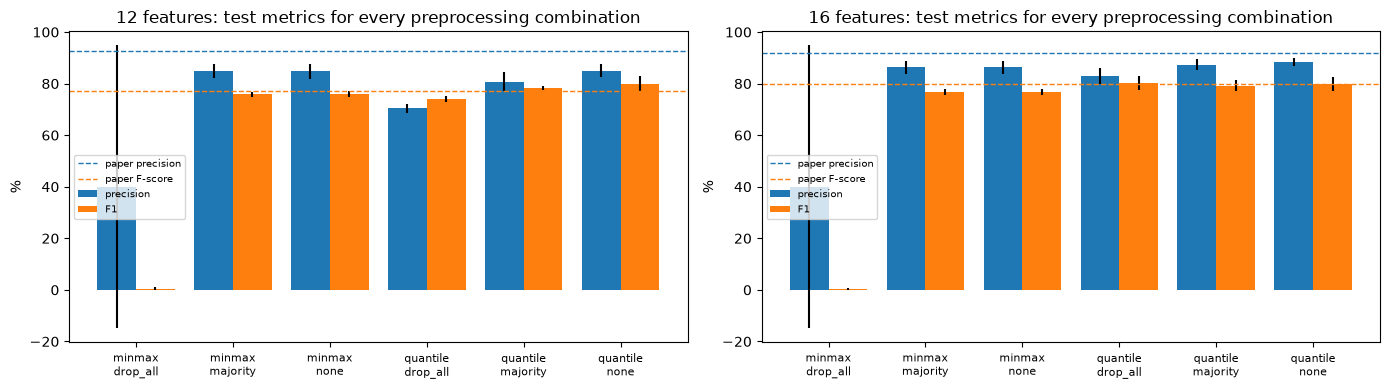

In [19]:
abl = GRID_DF.groupby(["features", "normalisation", "conflicts"], sort=False).agg(
    flows_kept=("n_kept", "mean"), precision=("precision", "mean"), precision_std=("precision", "std"), recall_attack=("recall", "mean"),
    f1=("f1", "mean"), f1_std=("f1", "std"), recall_normal=("tnr", "mean"), selected=("selected", "max")).round(1)
display(abl)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, nf in zip(axes, (12, 16)):
    sub = abl.loc[nf].reset_index(); lab = sub.normalisation + "\n" + sub.conflicts; x = np.arange(len(sub))
    ax.bar(x - 0.2, sub.precision, 0.4, yerr=sub.precision_std, label="precision", color="tab:blue"); ax.bar(x + 0.2, sub.f1, 0.4, yerr=sub.f1_std, label="F1", color="tab:orange")
    ax.axhline({12: 92.73, 16: 92.02}[nf], color="tab:blue", ls="--", lw=1, label="paper precision"); ax.axhline({12: 77.08, 16: 79.78}[nf], color="tab:orange", ls="--", lw=1, label="paper F-score")
    ax.set_xticks(x); ax.set_xticklabels(lab, fontsize=8); ax.set_ylabel("%"); ax.set_title(f"{nf} features: test metrics for every preprocessing combination"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 7. Side by side with the paper

Every number the paper reports and that can be tested is shown next to the notebook's mean over seeds. A claim is **reproduced** when the notebook's
value is within `TOL_PTS` = 2 percentage points; **not reached** / **exceeded** otherwise (with the gap); **cannot be checked** when the paper gives no
comparable number. The paper reports one run, so a +/- std is shown for orientation.

In [20]:
def verdict(paper, ours, tol=TOL_PTS):
    d = ours - paper
    return "reproduced" if abs(d) <= tol else ("exceeded" if d > 0 else "not reached")
S = {nf: final[final.features == nf] for nf in (12, 16)}
m = lambda nf, col: float(S[nf][col].mean()); sd = lambda nf, col: float(S[nf][col].std(ddof=0))
rows = []
def add(claim, paper, ours, std=None, v=None, note=""):
    rows.append(dict(claim=claim, paper=paper, notebook=(f"{ours:.2f}" + (f" +/- {std:.2f}" if std is not None else "")) if isinstance(ours, float) else ours,
                     verdict=v if v is not None else verdict(float(paper), ours), note=note))
add("16 features: precision (%)", 92.02, m(16, "precision"), sd(16, "precision"))
add("16 features: F-score (%)", 79.78, m(16, "f1"), sd(16, "f1"))
add("12 features: precision (%)", 92.73, m(12, "precision"), sd(12, "precision"))
add("12 features: F-score (%)", 77.08, m(12, "f1"), sd(12, "f1"))
add("12 features: recall of non-attack flows (%)", 95.0, m(12, "recall_normal"), sd(12, "recall_normal"), note="Fig. 4 text: 'about 95 %'")
add("16 features: recall of non-attack flows (%)", 95.0, m(16, "recall_normal"), sd(16, "recall_normal"), note="Fig. 4 text: 'about 95 %'")
add("16 features: recall of attack flows (%)", 71.0, m(16, "recall_attack"), sd(16, "recall_attack"), note="text: 'about 71 %'")
R12 = 100 * (0.7708 * 0.9273) / (2 * 0.9273 - 0.7708)
add("12 features: recall of attack flows (%)", round(R12, 2), m(12, "recall_attack"), sd(12, "recall_attack"), note="derived from the paper's P and F-score (not printed)")
dF, dP = m(16, "f1") - m(12, "f1"), m(12, "precision") - m(16, "precision")
add("F-score higher with 16 than with 12 features (paper +2.70)", "+2.70", f"{dF:+.2f}", v="reproduced" if dF > 0 else "not reached", note="direction only; the paper has a single run")
add("precision higher with 12 than with 16 features (paper +0.71)", "+0.71", f"{dP:+.2f}", v="reproduced" if dP > 0 else "not reached", note="direction only; differences this small are inside the seed spread")
for nf in (12, 16):
    L = np.array([r["hist"]["epoch_loss"] for r in BEST_RUNS[nf]]).mean(0); rise = float(np.max(np.diff(L))) if len(L) > 1 else 0.0
    nan = any(r["hist"]["nan"] for r in BEST_RUNS[nf]); ok = (L[-1] < L[0]) and rise <= 0.02 and not nan
    add(f"{nf} features: loss falls steadily, no jump / oscillation / NaN", "yes (Fig. 3)", f"loss {L[0]:.3f} -> {L[-1]:.3f}, largest epoch-to-epoch rise {rise:.3f}, NaN: {nan}", v="reproduced" if ok else "not reached")
gmax = max(max(r["hist"]["step_gmax"]) for nf in (12, 16) for r in BEST_RUNS[nf] if r["hist"]["step_gmax"])
add("gradient of the loss is bounded (eq. 3)", "bounded by 1 per unitary", f"largest |dloss/dangle| over all steps = {gmax:.3f} (bound 2 per angle, 2L overall)", v="reproduced" if gmax <= 2.0 + 1e-9 else "not reached",
    note="a mathematical property of exp(i theta sigma); here checked on every optimiser step")
mlp = ALLM[ALLM.model == "MLP on normalised features"].groupby("features").f1.mean()
for nf in (12, 16):
    add(f"{nf} features: QNN is worse than a classical neural network", "yes (qualitative)", f"QNN F1 {m(nf, 'f1'):.1f} vs MLP F1 {mlp[nf]:.1f} on the same features (before binarising)", v="reproduced" if m(nf, "f1") < mlp[nf] else "not reached")
add("classical networks reach 91.71-97.30 % on 6 application protocols [13]", "91.71-97.30 %", "different task and data", v="cannot be checked")
add("Table II: attack and normal means differ in the paper's direction", "12 of 12", f"{T2_DIR_OK} of 12", v="reproduced" if T2_DIR_OK == 12 else "not reached", note="sanity check of the column positions")
cmp_df = pd.DataFrame(rows); pd.set_option("display.max_colwidth", 90); display(cmp_df)
print(cmp_df.verdict.value_counts().to_string())
print(f"\nnotebook wall-clock so far: {(time.time() - T_NOTEBOOK_START) / 60:.1f} min | FAST_MODE = {FAST_MODE}")

,claim,paper,notebook,verdict,note
0,16 features: precision (%),92.02,83.00 +/- 2.74,not reached,
1,16 features: F-score (%),79.78,80.23 +/- 2.41,reproduced,
2,12 features: precision (%),92.73,80.71 +/- 3.29,not reached,
3,12 features: F-score (%),77.08,78.17 +/- 0.61,reproduced,
4,12 features: recall of non-attack flows (%),95.0,83.75 +/- 3.82,not reached,Fig. 4 text: 'about 95 %'
5,16 features: recall of non-attack flows (%),95.0,85.98 +/- 2.54,not reached,Fig. 4 text: 'about 95 %'
6,16 features: recall of attack flows (%),71.0,77.70 +/- 2.98,exceeded,text: 'about 71 %'
7,12 features: recall of attack flows (%),65.95,76.06 +/- 3.55,exceeded,derived from the paper's P and F-score (not printed)
8,F-score higher with 16 than with 12 features (paper +2.70),+2.70,+2.07,reproduced,direction only; the paper has a single run
9,precision higher with 12 than with 16 features (paper +0.71),+0.71,-2.30,not reached,direction only; differences this small are inside the seed spread


verdict
reproduced           9
not reached          5
exceeded             2
cannot be checked    1

notebook wall-clock so far: 14.4 min | FAST_MODE = False


## 8. Reading the paper critically

* **Binarisation is the bottleneck, and the paper says so.** One qubit per feature with a 0.5 threshold throws away almost everything. How much depends on the
  unstated normalisation: with plain min-max scaling most Moore features sit far below 0.5 and many flows of both classes collapse onto the same bit pattern; with
  a rank normalisation the bits are informative. Compare the rows of the ablation table.
* **"Conflict removal" is ambiguous and matters.** Removing *every* flow of a conflicting pattern can delete most of the training set; keeping the majority label
  or nothing gives very different models. The paper does not say which reading it used.
* **The circuit is classically trivial.** All data qubits interact only with the read-out qubit, so `<Z>` is a product of `n` two-term factors (section "Quantum Circuit
  Architecture"). It has `2n` parameters and a single "layer"; the capacity is that of a small product model on bit strings, not of a deep network. A random forest on the same bits
  is a stronger (and cheaper) classifier, and on the un-binarised features it is far stronger still.
* **No gradient explosion is not evidence of good training.** Boundedness holds for every circuit made of `exp(i theta sigma)` gates, trained or not. The flat, noise-free loss
  curve says the optimisation is stable, not that the model is accurate.
* **One run, no variance.** The paper reports a single run and a F-score difference of 2.7 points between 12 and 16 features. Over several seeds the spread of precision alone is of the same order.
* **Evaluation set is not fully specified.** Test size and class mix are not given, and precision depends directly on the ratio of attack to non-attack test flows. The Moore data have
  about 0.5 % attack flows overall; at that natural prevalence the same classifier would have a far lower precision.
* **Sets 1-10 are consecutive samples of one 24-hour trace from one site.** Training on sets 1, 2, 4, 7, 9, 10 and testing on 3, 5, 6, 8 mixes the same hosts and time of day.

## 9. Exercises

1. Change `GRID` to a single combination (`("quantile", "none")`) and rerun: how much of the paper's precision/F-score gap is explained by preprocessing alone?
2. Use 2 qubits per feature (two bits: quartiles of the rank-normalised value) as the paper proposes for the future. The closed form changes: derive and test it against the Qiskit circuit.
3. Add a third coupling layer `exp(-i psi_j Y_j Z_r)` or a second XX/ZZ block with new angles. Does the model stay a product over qubits? Can you still use the closed form?
4. Evaluate on the natural class mix (all non-attack flows of sets 3, 5, 6, 8 instead of the 485 sampled ones): how do precision and F-score change, and why?
5. Replace the ordinal "above/below the median" bit by the sign of the feature relative to its class means; is the information in the bits (distinct patterns, conflicting rows) higher?